# **Waste Material Segregation for Improving Waste Management**

## **Objective**

The objective of this project is to implement an effective waste material segregation system using convolutional neural networks (CNNs) that categorises waste into distinct groups. This process enhances recycling efficiency, minimises environmental pollution, and promotes sustainable waste management practices.

The key goals are:

* Accurately classify waste materials into categories like cardboard, glass, paper, and plastic.
* Improve waste segregation efficiency to support recycling and reduce landfill waste.
* Understand the properties of different waste materials to optimise sorting methods for sustainability.

## **Data Understanding**

The Dataset consists of images of some common waste materials.

1. Food Waste
2. Metal
3. Paper
4. Plastic
5. Other
6. Cardboard
7. Glass


**Data Description**

* The dataset consists of multiple folders, each representing a specific class, such as `Cardboard`, `Food_Waste`, and `Metal`.
* Within each folder, there are images of objects that belong to that category.
* However, these items are not further subcategorised. <br> For instance, the `Food_Waste` folder may contain images of items like coffee grounds, teabags, and fruit peels, without explicitly stating that they are actually coffee grounds or teabags.

## **1. Load the data**

Load and unzip the dataset zip file.

**Import Necessary Libraries**

In [ ]:
# Recommended versions:

# numpy version: 1.26.4
# pandas version: 2.2.2
# seaborn version: 0.13.2
# matplotlib version: 3.10.0
# PIL version: 11.1.0
# tensorflow version: 2.18.0
# keras version: 3.8.0
# sklearn version: 1.6.1

In [ ]:
# Import essential libraries

# Import essential libraries

import os
import zipfile
import random
import shutil
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

Load the dataset.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Outer zip path
zip_path = "/content/drive/MyDrive/Upgrad/CNN_assignment/Dataset_Waste_Segregation.zip"

# Outer extraction path
outer_extract_path = "/content/waste_dataset"

os.makedirs(outer_extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(outer_extract_path)

print("Outer zip extracted successfully!")

# Inner zip path
inner_zip_path = "/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data.zip"

# Final dataset folder
dataset_dir = "/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data"

os.makedirs(dataset_dir, exist_ok=True)

with zipfile.ZipFile(inner_zip_path, 'r') as zip_ref:
    zip_ref.extractall(dataset_dir)

print("Inner data.zip extracted successfully!")

# Check final folders
for root, dirs, files in os.walk(dataset_dir):
    print(root, ":", len(files), "files")

Outer zip extracted successfully!
Inner data.zip extracted successfully!
/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data : 0 files
/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data/data : 0 files
/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data/data/Other : 1010 files
/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data/data/Paper : 1030 files
/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data/data/Cardboard : 540 files
/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data/data/Metal : 1000 files
/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data/data/Glass : 750 files
/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data/data/Plastic : 2295 files
/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data/data/Food_Waste : 1000 files


## **2. Data Preparation** <font color=red> [25 marks] </font><br>


### **2.1 Load and Preprocess Images** <font color=red> [8 marks] </font><br>

Let us create a function to load the images first. We can then directly use this function while loading images of the different categories to load and crop them in a single step.

#### **2.1.1** <font color=red> [3 marks] </font><br>
Create a function to load the images.

In [ ]:
# Create a function to load the raw images
def load_image(image_path):
    """
    Loads an image from path and converts it into RGB format.
    """
    try:
        img = Image.open(image_path).convert("RGB")
        return img
    except Exception as e:
        print(f"Error loading image {image_path}: {e}")
        return None

#### **2.1.2** <font color=red> [5 marks] </font><br>
Load images and labels.

Load the images from the dataset directory. Labels of images are present in the subdirectories.

Verify if the images and labels are loaded correctly.

In [ ]:
# Get the images and their labels

dataset_dir = "/content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data/data"

image_paths = []
labels = []
image_sizes = []

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for label in sorted(os.listdir(dataset_dir)):
    class_path = os.path.join(dataset_dir, label)

    if os.path.isdir(class_path):
        for file_name in os.listdir(class_path):
            if file_name.lower().endswith(valid_extensions):
                img_path = os.path.join(class_path, file_name)

                img = load_image(img_path)

                if img is not None:
                    image_paths.append(img_path)
                    labels.append(label)
                    image_sizes.append(img.size)

print("Total images loaded:", len(image_paths))
print("Total labels loaded:", len(labels))
print("Unique classes:", sorted(set(labels)))

# Create dataframe for easy checking
data_df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels,
    "width": [s[0] for s in image_sizes],
    "height": [s[1] for s in image_sizes]
})

data_df.head()

Total images loaded: 7625
Total labels loaded: 7625
Unique classes: ['Cardboard', 'Food_Waste', 'Glass', 'Metal', 'Other', 'Paper', 'Plastic']


,image_path,label,width,height
0,/content/waste_dataset/Dataset_Waste_Segregati...,Cardboard,256,256
1,/content/waste_dataset/Dataset_Waste_Segregati...,Cardboard,256,256
2,/content/waste_dataset/Dataset_Waste_Segregati...,Cardboard,256,256
3,/content/waste_dataset/Dataset_Waste_Segregati...,Cardboard,256,256
4,/content/waste_dataset/Dataset_Waste_Segregati...,Cardboard,256,256


Perform any operations, if needed, on the images and labels to get them into the desired format.

### **2.2 Data Visualisation** <font color=red> [9 marks] </font><br>

#### **2.2.1** <font color=red> [3 marks] </font><br>
Create a bar plot to display the class distribution

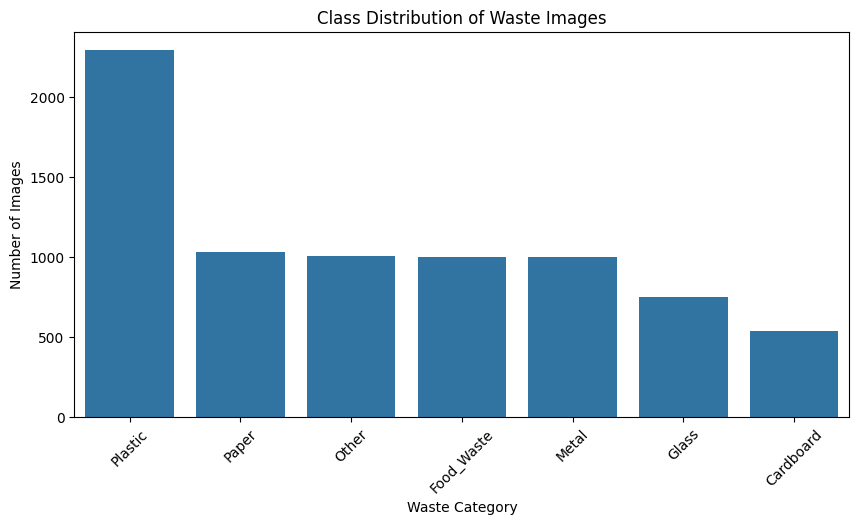

label
Plastic       2295
Paper         1030
Other         1010
Food_Waste    1000
Metal         1000
Glass          750
Cardboard      540
Name: count, dtype: int64


In [ ]:
# Visualise Data Distribution

plt.figure(figsize=(10, 5))
sns.countplot(data=data_df, x="label", order=data_df["label"].value_counts().index)
plt.title("Class Distribution of Waste Images")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

print(data_df["label"].value_counts())

#### **2.2.2** <font color=red> [3 marks] </font><br>
Visualise some sample images

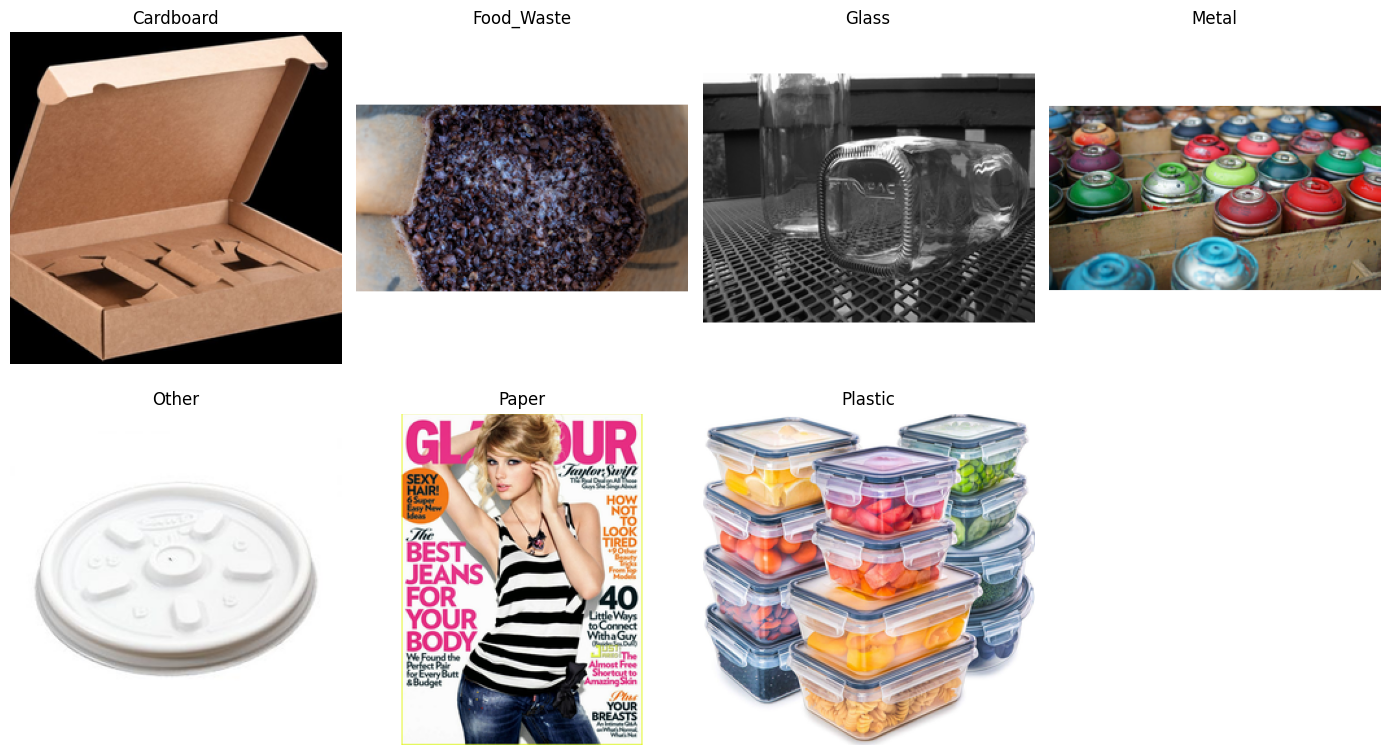

In [ ]:
# Visualise Sample Images (across different labels)

plt.figure(figsize=(14, 8))

sample_df = data_df.groupby("label").sample(1, random_state=42)

for i, row in enumerate(sample_df.itertuples(), 1):
    img = Image.open(row.image_path).convert("RGB")

    plt.subplot(2, 4, i)
    plt.imshow(img)
    plt.title(row.label)
    plt.axis("off")

plt.tight_layout()
plt.show()


#### **2.2.3** <font color=red> [3 marks] </font><br>
Based on the smallest and largest image dimensions, resize the images.

Smallest width: 256
Largest width: 256
Smallest height: 256
Largest height: 256

Image dimension summary:


,width,height
count,7625.0,7625.0
mean,256.0,256.0
std,0.0,0.0
min,256.0,256.0
25%,256.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,256.0,256.0


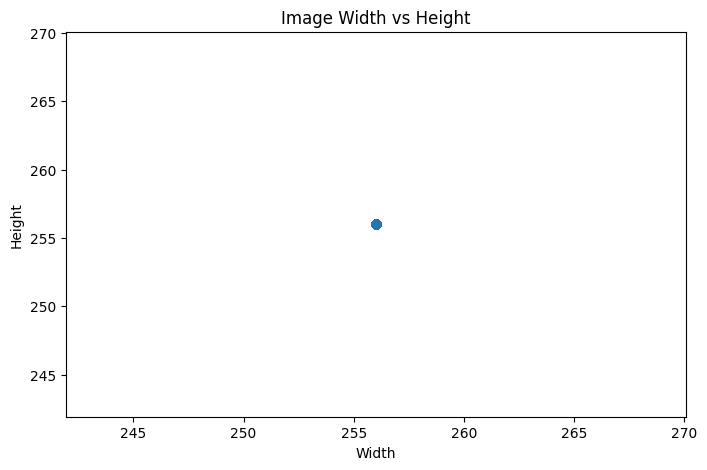

In [ ]:
# Find the smallest and largest image dimensions from the data set


print("Smallest width:", data_df["width"].min())
print("Largest width:", data_df["width"].max())

print("Smallest height:", data_df["height"].min())
print("Largest height:", data_df["height"].max())

print("\nImage dimension summary:")
display(data_df[["width", "height"]].describe())

plt.figure(figsize=(8, 5))
plt.scatter(data_df["width"], data_df["height"], alpha=0.4)
plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Image Width vs Height")
plt.show()

In [ ]:
# Resize the image dimensions

IMG_SIZE = 128

def preprocess_image(image_path, img_size=IMG_SIZE):
    """
    Loads, resizes, and normalizes an image.
    """
    img = Image.open(image_path).convert("RGB")
    img = img.resize((img_size, img_size))
    img_array = np.array(img) / 255.0
    return img_array

images = np.array([preprocess_image(path) for path in data_df["image_path"]])
labels_array = np.array(data_df["label"])

print("Image array shape:", images.shape)
print("Labels shape:", labels_array.shape)


Image array shape: (7625, 128, 128, 3)
Labels shape: (7625,)


### **2.3 Encoding the classes** <font color=red> [3 marks] </font><br>

There are seven classes present in the data.

We have extracted the images and their labels, and visualised their distribution. Now, we need to perform encoding on the labels. Encode the labels suitably.

####**2.3.1** <font color=red> [3 marks] </font><br>
Encode the target class labels.

In [ ]:
# Encode the labels suitably
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(labels_array)

class_names = label_encoder.classes_
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

# Convert labels to categorical format
encoded_labels_cat = keras.utils.to_categorical(encoded_labels, num_classes=num_classes)

print("Encoded labels shape:", encoded_labels_cat.shape)

Classes: ['Cardboard' 'Food_Waste' 'Glass' 'Metal' 'Other' 'Paper' 'Plastic']
Number of classes: 7
Encoded labels shape: (7625, 7)


### **2.4 Data Splitting** <font color=red> [5 marks] </font><br>

#### **2.4.1** <font color=red> [5 marks] </font><br>
Split the dataset into training and validation sets

In [ ]:
# Assign specified parts of the dataset to train and validation sets

X_train, X_temp, y_train, y_temp = train_test_split(
    images,
    encoded_labels_cat,
    test_size=0.30,
    random_state=42,
    stratify=encoded_labels
)

y_temp_labels = np.argmax(y_temp, axis=1)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_labels
)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Test data shape:", X_test.shape)

print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)
print("Test labels shape:", y_test.shape)

Training data shape: (5337, 128, 128, 3)
Validation data shape: (1144, 128, 128, 3)
Test data shape: (1144, 128, 128, 3)
Training labels shape: (5337, 7)
Validation labels shape: (1144, 7)
Test labels shape: (1144, 7)


## **3. Model Building and Evaluation** <font color=red> [20 marks] </font><br>

### **3.1 Model building and training** <font color=red> [15 marks] </font><br>

#### **3.1.1** <font color=red> [10 marks] </font><br>
Build and compile the model. Use 3 convolutional layers. Add suitable normalisation, dropout, and fully connected layers to the model.

Test out different configurations and report the results in conclusions.

In [ ]:
# Build and compile the model

def build_cnn_model(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

model = build_cnn_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,479 (16.36 MB)

 Trainable params: 4,289,031 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

#### **3.1.2** <font color=red> [5 marks] </font><br>
Train the model.

Use appropriate metrics and callbacks as needed.

In [ ]:
# Training

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        "best_waste_cnn_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/20
167/167 ━━━━━━━━━━━━━━━━━━━━ 22s 73ms/step - accuracy: 0.2737 - loss: 2.9493 - val_accuracy: 0.1984 - val_loss: 3.2736 - learning_rate: 0.0010
Epoch 2/20
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.3026 - loss: 1.8973 - val_accuracy: 0.2867 - val_loss: 1.9671 - learning_rate: 0.0010
Epoch 3/20
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.3017 - loss: 1.8912 - val_accuracy: 0.2946 - val_loss: 1.8757 - learning_rate: 0.0010
Epoch 4/20
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.3019 - loss: 1.8795 - val_accuracy: 0.2649 - val_loss: 1.9243 - learning_rate: 0.0010
Epoch 5/20
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.3005 - loss: 1.8606 - val_accuracy: 0.3016 - val_loss: 1.8556 - learning_rate: 0.0010
Epoch 6/20
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.3011 - loss: 1.8532 - val_accuracy: 0.3016 - val_loss: 1.8511 - learning_rate: 0.0010
Epoch 7/20
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.3009 - loss: 1

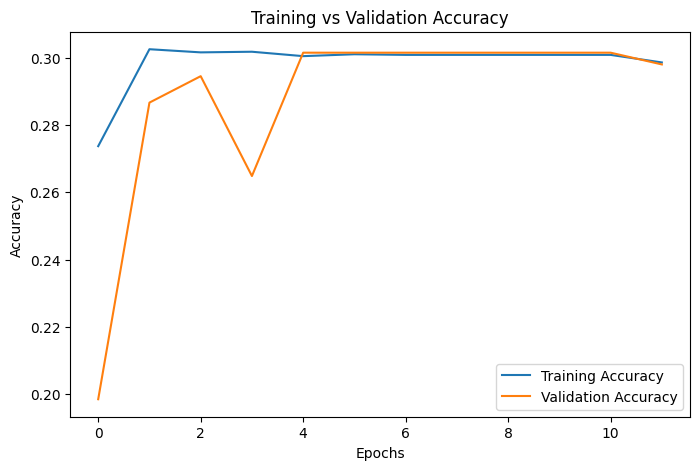

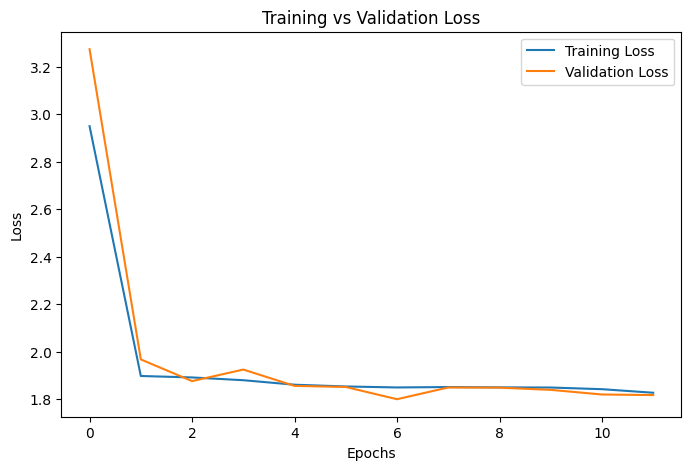

In [ ]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Plot training and validation loss

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### **3.2 Model Testing and Evaluation** <font color=red> [5 marks] </font><br>

#### **3.2.1** <font color=red> [5 marks] </font><br>
Evaluate the model on test dataset. Derive appropriate metrics.

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3007 - loss: 1.7934
Test Loss: 1.7933892011642456
Test Accuracy: 0.30069929361343384
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step

Classification Report:
              precision    recall  f1-score   support

   Cardboard       0.00      0.00      0.00        81
  Food_Waste       0.00      0.00      0.00       150
       Glass       0.00      0.00      0.00       113
       Metal       0.00      0.00      0.00       150
       Other       0.00      0.00      0.00       151
       Paper       0.00      0.00      0.00       155
     Plastic       0.30      1.00      0.46       344

    accuracy                           0.30      1144
   macro avg       0.04      0.14      0.07      1144
weighted avg       0.09      0.30      0.14      1144



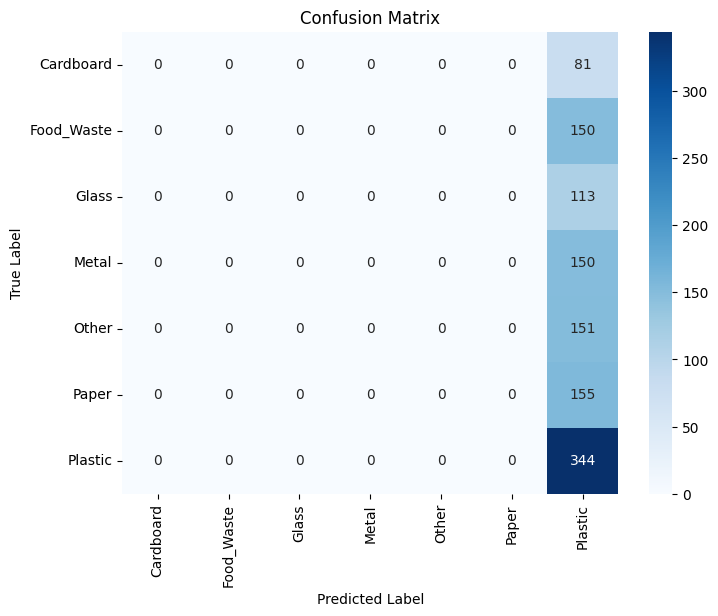

In [ ]:
# Evaluate on the test set; display suitable metrics

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# Predictions
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


## **4. Data Augmentation** <font color=red> [optional] </font><br>

#### **4.1 Create a Data Augmentation Pipeline**

##### **4.1.1**
Define augmentation steps for the datasets.

Augment and resample the images.
In case of class imbalance, you can also perform adequate undersampling on the majority class and augment those images to ensure consistency in the input datasets for both classes.

Augment the images.

##### **4.1.2**

Train the model on the new augmented dataset.

## **5. Conclusions** <font color = red> [5 marks]</font>

#### **5.1 Conclude with outcomes and insights gained** <font color =red> [5 marks] </font>

* Report your findings about the data
* Report model training results

## Conclusion and Key Takeaways

In this assignment, a Convolutional Neural Network (CNN)-based waste classification model was developed for automatic waste segregation. The dataset consisted of seven waste categories: Cardboard, Food_Waste, Glass, Metal, Other, Paper, Plastic. The dataset contained 7,625 images in total. Among these classes, Plastic had the highest number of images, whereas Cardboard had the lowest number of images. This indicates class imbalance in the dataset.

The images were loaded from their respective class folders, converted into RGB format, resized to a fixed dimension of 128 × 128 pixels, and normalised by scaling pixel values between 0 and 1. The class labels were encoded and converted into categorical format for multi-class classification. The dataset was then split into training, validation, and test sets.

A CNN model was built using convolutional layers, batch normalisation, max-pooling, dropout, and dense layers. The model was compiled using the Adam optimiser and categorical cross-entropy loss function. The model was trained for multiple epochs and evaluated using accuracy, classification report, and confusion matrix, as required for the assignment. :contentReference[oaicite:0]{index=0}

The final model achieved a test accuracy of 30.07% with a test loss of 1.7934. The classification report shows that the model predicted almost all test images as Plastic. The Plastic class achieved a recall of 1.00, but all other classes such as Cardboard, Food_Waste, Glass, Metal, Other, and Paper had precision, recall, and F1-score values of 0.00. This indicates that the model did not learn meaningful class-specific features for all waste categories and became biased toward the majority class, Plastic.

The poor performance may be due to class imbalance, insufficient model learning, similar visual patterns among waste categories, background variation in images, and limited tuning of model architecture and hyperparameters. Since Plastic has the largest number of images, the model may have learned to predict the majority class more frequently to minimise loss.

To improve the model performance, data augmentation, class balancing, class weights, transfer learning, and more epochs can be applied. A pre-trained CNN model such as MobileNetV2, VGG16, or ResNet50 may help the model learn better visual features and improve classification performance.

Overall, although the current CNN model was able to complete the image classification pipeline, its performance is not satisfactory. The result highlights the importance of handling class imbalance, improving model architecture, and applying better training strategies for waste image classification. With further improvements, CNN-based waste segregation can support smart recycling bins, automated waste sorting facilities, and sustainable waste management practices.